In [2]:
# Import Libraries
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Dataset
df = pd.read_csv(r'C:\Users\sunda\OneDrive\Desktop\Python_works\job_postings_flat.csv')



In [3]:
# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(
    lambda x: ast.literal_eval(x)
    if pd.notna(x)
    else x
)



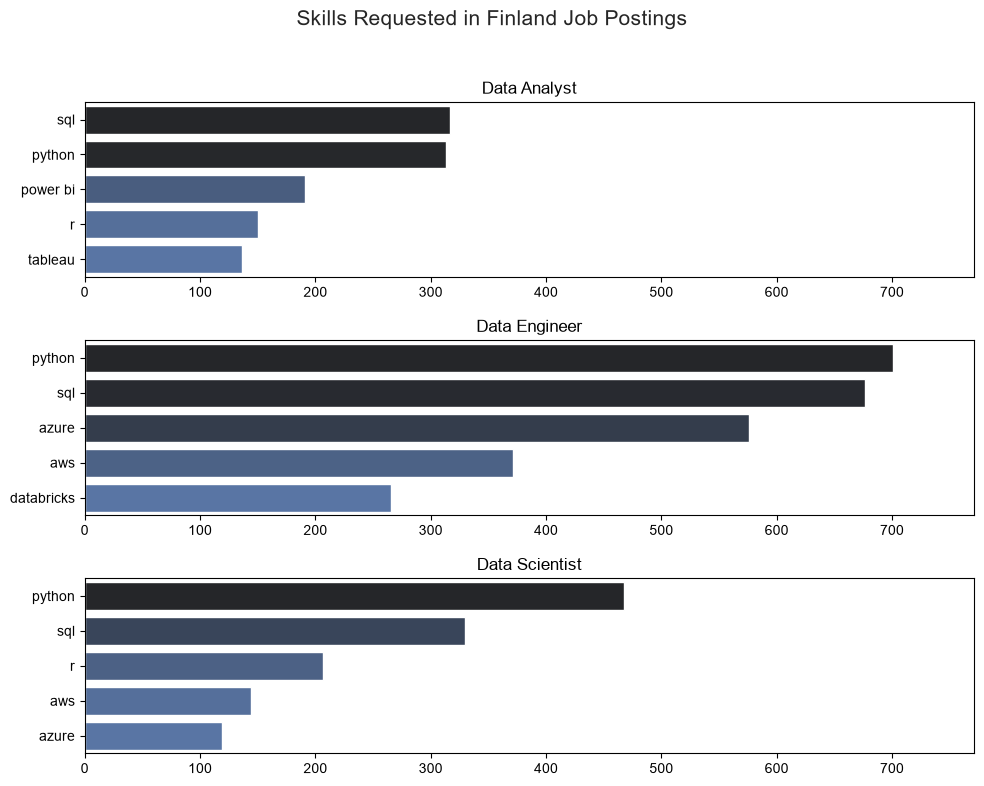

In [4]:
# Filter for Finland
df_fin = df[df['job_country'] == 'Finland'].copy()

# Explode skills
df_skills = df_fin.explode('job_skills')

# Count skills by role
df_skills_count = (
    df_skills
    .groupby(['job_skills', 'job_title_short'])
    .size()
    .reset_index(name='skill_count')
)

# Sort counts descending
df_skills_count = (
    df_skills_count
    .sort_values(by='skill_count', ascending=False)
)

# Roles to display
job_titles = [
    'Data Analyst',
    'Data Engineer',
    'Data Scientist'
]

# Create figure
fig, ax = plt.subplots(
    len(job_titles),
    1,
    figsize=(10, 8)
)

sns.set_theme(style='ticks')

# Dynamic scale for Finland
max_count = (
    df_skills_count[
        df_skills_count['job_title_short'].isin(job_titles)
    ]['skill_count']
    .max()
)

for i, job_title in enumerate(job_titles):

    # Top 5 skills for role
    df_plot = (
        df_skills_count[
            df_skills_count['job_title_short'] == job_title
        ]
        .nlargest(5, 'skill_count')
    )

    sns.barplot(
        data=df_plot,
        x='skill_count',
        y='job_skills',
        order=df_plot['job_skills'],
        ax=ax[i],
        hue='skill_count',
        palette='dark:b_r',
        legend=False
    )

    # ax[i].invert_yaxis()

    ax[i].set_title(job_title)

    ax[i].set_ylabel('')
    ax[i].set_xlabel('')

    ax[i].set_xlim(0, max_count * 1.1)

# Main title
fig.suptitle(
    'Skills Requested in Finland Job Postings',
    fontsize=15
)

# Spacing
fig.tight_layout(
    h_pad=1.2,
    rect=[0, 0, 1, 0.96]
)

plt.show()

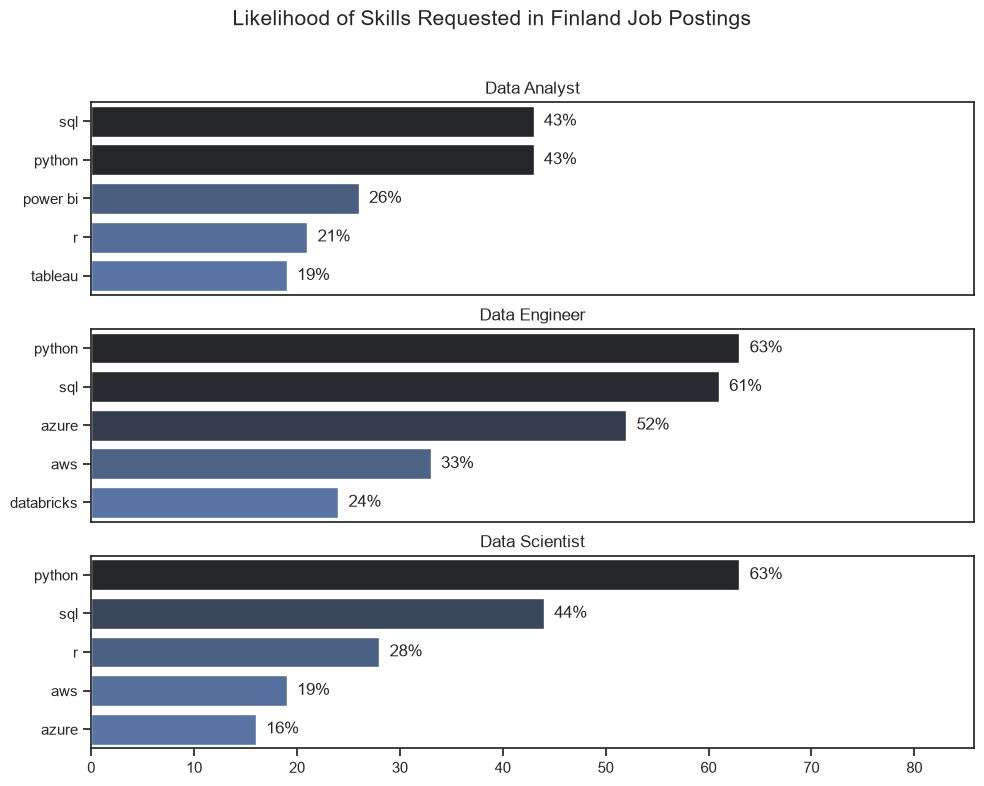

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Data Analyst,Data Analyst,"New York, NY",via CareerBuilder,Full-time,False,"New York, United States",2023-01-01 00:00:04,False,False,United States,NaN,NaN,NaN,Metasys Technologies,"[sql, snowflake, visio, jira, confluence]","{'analyst_tools': ['visio'], 'async': ['jira',..."
1,Data Analyst,Data Analyst,"Washington, DC",via CareerBuilder,Full-time,False,"New York, United States",2023-01-01 00:00:22,False,True,United States,NaN,NaN,NaN,Guidehouse,"[sql, python, r, azure, snowflake, databricks,...","{'analyst_tools': ['tableau', 'excel'], 'cloud..."
2,Data Analyst,Data Analyst,"Fairfax, VA",via CareerBuilder,Full-time,False,"New York, United States",2023-01-01 00:00:24,False,False,United States,NaN,NaN,NaN,Protask,"[sql, jira]","{'async': ['jira'], 'programming': ['sql']}"
3,Senior Data Analyst,Senior Data Analyst / Platform Experience,"Worcester, MA",via LinkedIn,Full-time,False,"New York, United States",2023-01-01 00:00:27,False,True,United States,NaN,NaN,NaN,Atria Wealth Solutions,"[sql, atlassian, jira]","{'async': ['jira'], 'other': ['atlassian'], 'p..."
4,Data Analyst,Data Analyst,"Sunnyvale, CA",via CareerBuilder,Full-time,False,"California, United States",2023-01-01 00:00:38,False,False,United States,NaN,NaN,NaN,"ICONMA, LLC","[sql, python]","{'programming': ['sql', 'python']}"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008265,Senior Data Scientist,Senior Data Scientist - Product,Anywhere,KenyaRemoteJobs,Full-time,True,Kenya,2026-10-31 17:03:26,False,False,Kenya,year,170000.0,NaN,Verified Direct Employer,"[sql, python, r, go, sas, looker, sas]","{'analyst_tools': ['looker', 'sas'], 'programm..."
2008266,Data Engineer,EEG Experiment and Data Engineer,"Ajmer, Rajasthan, India",LinkedIn,Full-time,False,India,2026-10-31 18:05:07,False,False,India,NaN,NaN,NaN,WABO,"[python, r, matlab]","{'programming': ['python', 'r', 'matlab']}"
2008267,Business Analyst,Product Analyst Inten,Anywhere,LinkedIn ‏لبنان,Internship,True,Lebanon,2026-10-31 20:01:46,False,False,Lebanon,NaN,NaN,NaN,Helix,NaN,NaN
2008268,Machine Learning Engineer,"Data Scientist - ML & AI Solutions (Contract, ...","Longford, Ireland",JobMESH,Full-time,False,Ireland,2026-10-31 21:03:21,False,False,Ireland,NaN,NaN,NaN,MCS Group,"[sql, python]","{'programming': ['sql', 'python']}"


In [ ]:
# get the value count
df_jobs_total = (
    df_fin['job_title_short']
    .value_counts()
    .reset_index(name='jobs_count')
)

# merge
df_skill_perc = pd.merge(
    df_skills_count,
    df_jobs_total,
    how='left',
    on='job_title_short'
)

# calculate percentage FIRST
df_skill_perc['skill_percent'] = (
    (df_skill_perc['skill_count'] / df_skill_perc['jobs_count']) * 100
).round(0).astype(int)

# Create figure
fig, ax = plt.subplots(
    len(job_titles),
    1,
    figsize=(10, 8)
)

# Maximum percentage for consistent scale
max_pct = df_skill_perc['skill_percent'].max()

for i, job_title in enumerate(job_titles):

    df_plot = (
        df_skill_perc[
            df_skill_perc['job_title_short'] == job_title
        ]
        .nlargest(5, 'skill_percent')
    )

    sns.barplot(
        data=df_plot,
        x='skill_percent',
        y='job_skills',
        order=df_plot['job_skills'],
        ax=ax[i],
        hue='skill_percent',
        palette='dark:b_r',
        legend=False
    )

    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_xlim(0, max_pct * 1.1)

    # label the percentage
    for n, v in enumerate(df_plot['skill_percent']):
        ax[i].text(v + 1, n, f'{v}%', va='center')

    # hide x-axis labels except bottom chart
    if i != len(job_titles) - 1:
        ax[i].set_xticks([])

fig.suptitle(
    'Likelihood of Skills Requested in Finland Job Postings',
    fontsize=15
)

fig.tight_layout(
    h_pad=.8,
    rect=[0, 0, 1, 0.96]
)

plt.show()



In [3]:
df

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Data Analyst,Data Analyst,"New York, NY",via CareerBuilder,Full-time,False,"New York, United States",2023-01-01 00:00:04,False,False,United States,NaN,NaN,NaN,Metasys Technologies,"['sql', 'snowflake', 'visio', 'jira', 'conflue...","{'analyst_tools': ['visio'], 'async': ['jira',..."
1,Data Analyst,Data Analyst,"Washington, DC",via CareerBuilder,Full-time,False,"New York, United States",2023-01-01 00:00:22,False,True,United States,NaN,NaN,NaN,Guidehouse,"['sql', 'python', 'r', 'azure', 'snowflake', '...","{'analyst_tools': ['tableau', 'excel'], 'cloud..."
2,Data Analyst,Data Analyst,"Fairfax, VA",via CareerBuilder,Full-time,False,"New York, United States",2023-01-01 00:00:24,False,False,United States,NaN,NaN,NaN,Protask,"['sql', 'jira']","{'async': ['jira'], 'programming': ['sql']}"
3,Senior Data Analyst,Senior Data Analyst / Platform Experience,"Worcester, MA",via LinkedIn,Full-time,False,"New York, United States",2023-01-01 00:00:27,False,True,United States,NaN,NaN,NaN,Atria Wealth Solutions,"['sql', 'atlassian', 'jira']","{'async': ['jira'], 'other': ['atlassian'], 'p..."
4,Data Analyst,Data Analyst,"Sunnyvale, CA",via CareerBuilder,Full-time,False,"California, United States",2023-01-01 00:00:38,False,False,United States,NaN,NaN,NaN,"ICONMA, LLC","['sql', 'python']","{'programming': ['sql', 'python']}"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008265,Senior Data Scientist,Senior Data Scientist - Product,Anywhere,KenyaRemoteJobs,Full-time,True,Kenya,2026-10-31 17:03:26,False,False,Kenya,year,170000.0,NaN,Verified Direct Employer,"['sql', 'python', 'r', 'go', 'sas', 'looker', ...","{'analyst_tools': ['looker', 'sas'], 'programm..."
2008266,Data Engineer,EEG Experiment and Data Engineer,"Ajmer, Rajasthan, India",LinkedIn,Full-time,False,India,2026-10-31 18:05:07,False,False,India,NaN,NaN,NaN,WABO,"['python', 'r', 'matlab']","{'programming': ['python', 'r', 'matlab']}"
2008267,Business Analyst,Product Analyst Inten,Anywhere,LinkedIn ‏لبنان,Internship,True,Lebanon,2026-10-31 20:01:46,False,False,Lebanon,NaN,NaN,NaN,Helix,NaN,NaN
2008268,Machine Learning Engineer,"Data Scientist - ML & AI Solutions (Contract, ...","Longford, Ireland",JobMESH,Full-time,False,Ireland,2026-10-31 21:03:21,False,False,Ireland,NaN,NaN,NaN,MCS Group,"['sql', 'python']","{'programming': ['sql', 'python']}"
